In [6]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


Neighborhood rankings by reported incidents in 2025
 Rank              Neighborhood  Reported Incidents
    1  Lincoln–Lemington–Belmar                   1
    2                 St. Clair                   8
    3                 Ridgemont                  17
    4             New Homestead                  21
    5            Chartiers City                  23
    6            Swisshelm Park                  27
    7             East Carnegie                  32
    8               Summer Hill                  33
    9                 Fairywood                  35
   10                    Esplen                  38
   11              Mount Oliver                  41
   11             Regent Square                  41
   13                Glen Hazel                  48
   14                      Hays                  49
   15         Arlington Heights                  51
   16                   Oakwood                  57
   17                   Windgap                  58
   18       

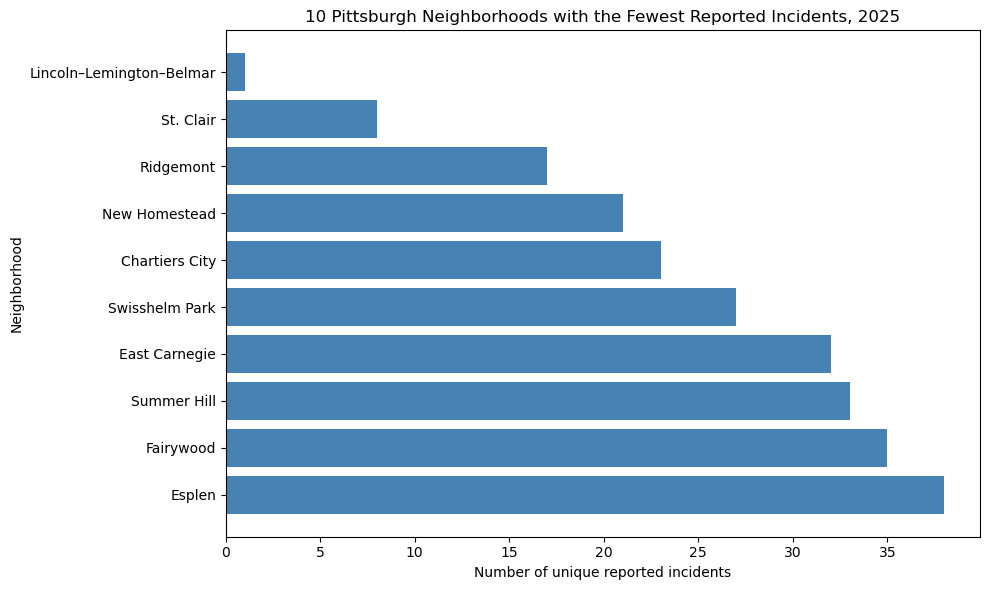

In [2]:
## Project - SEGMENT CREATED BY RICHARD A. BAMFORD

import pandas as pd
import matplotlib.pyplot as plt

# Loading DataSet ---

data = pd.read_excel("incidents_2024_sep2026.xlsx")

data = data[data["ReportedYear"] == 2025].copy()

data = data.dropna(subset=["Neighborhood", "Report_Number"])

data["Neighborhood"] = data["Neighborhood"].str.strip()

data["Neighborhood"] = data["Neighborhood"].replace({
    "Lincoln�Lemington�Belmar": "Lincoln-Lemington-Belmar",
    "Spring Hill�City View": "Spring Hill-City View"
})

ranking = (
    data.groupby("Neighborhood")["Report_Number"]
    .nunique()
    .reset_index(name="Reported Incidents")
)

ranking = ranking.sort_values(
    ["Reported Incidents", "Neighborhood"]
).reset_index(drop=True)

ranking["Rank"] = (
    ranking["Reported Incidents"]
    .rank(method="min")
    .astype(int)
)
ranking = ranking[["Rank", "Neighborhood", "Reported Incidents"]]

# 7. Display the complete ranking
print("Neighborhood rankings by reported incidents in 2025")
print(ranking.to_string(index=False))

# 8. Display the neighborhood(s) with the lowest count
lowest_count = ranking["Reported Incidents"].min()
best = ranking[ranking["Reported Incidents"] == lowest_count]

print("\nFewest reported incidents:")
print(best.to_string(index=False))

# 9. Chart the 10 neighborhoods with the fewest incidents
top_ten = ranking.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_ten["Neighborhood"],
    top_ten["Reported Incidents"],
    color="steelblue"
)
plt.gca().invert_yaxis()
plt.xlabel("Number of unique reported incidents")
plt.ylabel("Neighborhood")
plt.title("10 Pittsburgh Neighborhoods with the Fewest Reported Incidents, 2025")
plt.tight_layout()
plt.show()